# Intelligent Agents: Reflex-Based Agents for the Vacuum-cleaner World

Student Name: Phạm Minh Dương (3123410065), Phạm Tấn Đạt (3123410072),
Đỗ Quốc Việt (3123410426), Nguyễn Xuân Đăng (3123410077)

I have used the following AI tools: VS Code AI Assistant, Python Gymnasium Documentation

I understand that my submission needs to be my own work

## Learning Outcomes

* Design and build a simulation environment that models sensor inputs, actuator effects, and performance measurement.
* Apply core AI concepts by implementing the agent function for a simple and model-based reflex agents that respond to environmental percepts.
* Practice how the environment and the agent function interact.
* Analyze agent performance through controlled experiments across different environment configurations.
* Graduate Students: Develop strategies for handling uncertainty and imperfect information in autonomous agent systems.

## Instructions

Total Points: 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 

### AI Use

Here are some guidelines that will make it easier for you:

* __Don't:__ Rely on AI auto completion. You will waste a lot of time trying to figure out how the suggested code relates to what we do in class. Turn off AI code completion (e.g., Copilot) in your IDE.
* __Don't:__ Do not submit code/text that you do not understand or have not checked to make sure that it is complete and correct.
* __Do:__ Use AI for debugging and letting it explain code and concepts from class.

### Using Visual Studio Code

Follow [HOWTO Setup the Used Tools] to set up your Jupyter Notebook environment.
You can use `Export` (click on `...` in the menu bar) in VS Code to save your notebook as a HTML file. Don't forget to run all blocks before, so the HTML file contains the output of the executed code.

### Using Google Colab

In Colab you need to save the notebook on GoogleDrive to work with it. For this you need to mount your google dive and change to the correct directory. The following code will try to do this if you are on Colab.

In [2]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

Once you are done with the assignment and have run all code blocks using `Runtime/Run all`, you can convert your notebook on GoogleDrive into HTML
using: [Convert a Jupyter Notebook to HTML using Colab](https://colab.research.google.com/github/mhahsler/Introduction_to_Artificial_Intelligence/blob/master/HOWTOs/colab_to_html.ipynb).

## Introduction

In this assignment you will implement a simulator environment for an automatic vacuum cleaner robot, a set of different reflex-based agent programs, and perform a comparison study for cleaning a single room. Focus on the __cleaning phase__ which starts when the robot is activated and ends when the last dirty square in the room has been cleaned. Someone else will take care of the agent program needed to navigate back to the charging station after the room is clean.

## PEAS description of the cleaning phase

The PEAS description is used in the design phase for an intelligent agent. Make sure your implementations follow this description:

* __Performance Measure:__ Each action costs 1 energy unit. The performance is measured as the sum of the energy units used to clean the whole room.

* __Environment:__ A room with $n \times n$ squares where $n = 5$. Dirt is randomly placed on each square with probability $p = 0.2$. For simplicity, you can assume that the agent knows the size and the layout of the room (i.e., it knows $n$). To start, the agent is placed on a random square.

* __Actuators:__ The agent can clean the current square (action `suck`) or move to an adjacent square by going `north`, `east`, `south`, or `west`.

* __Sensors:__ Four bumper sensors, one for north, east, south, and west; a dirt sensor reporting dirt in the current square.  


## The agent program for a simple randomized agent

To show the structure of an agent program, I implement here a simple randomized agent that chooses its actions randomly.

The agent program is implemented as a function that gets sensor information (the current percepts) as the arguments. 
We will use the parameters:

* `bumpers`: A dictionary with boolean entries for the for bumper sensors `north`, `east`, `west`, `south`. E.g., if the agent is on the north-west corner, `bumpers` will be `{"north" : True, "east" : False, "south" : False, "west" : True}`.
* `dirty`: A boolean representing the dirt sensor.

The agent returns the chosen action as a string.

Here is an example implementation for the agent program of a simple randomized agent:  

In [3]:
# Google Colab or if you are missing a package: Uncomment the %pip command below, run this block, and restart the session.
# %pip install -q "numpy>=1.26,<3"

In [4]:
import numpy as np

actions = ["north", "east", "west", "south", "suck"]

def simple_randomized_agent(bumpers, dirty):
    return np.random.choice(actions)

In [5]:
# define percepts (current location is NW corner and it is dirty)
bumpers = {"north" : True, "east" : False, "south" : False, "west" : True}
dirty = True

# call agent program function with percepts and it returns an action
simple_randomized_agent(bumpers, dirty)

np.str_('south')

__Note:__ This is not a rational intelligent agent. It ignores its sensors and may bump into a wall repeatedly or not clean a dirty square. You will be asked to implement rational agents below.

## Simple environment example

I show here how to implement a simple simulation environment that supplies the agent program with its percepts and evaluates the agent's actions.
As an example, I implement a room of infinite in size (bumpers are always `False`) where every square is always dirty, even if the agent cleans it. The environment function returns a different performance measure than the one specified in the PEAS description! Since the room is infinite and all squares are constantly dirty, the agent can never clean the whole room. Your implementation needs to implement the **correct performance measure.** The energy budget of the agent is specified as `max_steps`. 

In [6]:
def simple_environment(agent_function, max_steps, verbose = True):
    num_cleaned = 0
    
    for i in range(max_steps):
        dirty = True
        bumpers = {"north" : False, "south" : False, "west" : False, "east" : False}

        action = agent_function(bumpers, dirty)
        if (verbose): print("step", i , "- action:", action) 
        
        if (action == "suck"): 
            num_cleaned = num_cleaned + 1
        
    return num_cleaned
        


Do one simulation run with a simple randomized agent that has enough energy for 20 steps.

In [7]:
simple_environment(simple_randomized_agent, max_steps = 20)

step 0 - action: west
step 1 - action: south
step 2 - action: west
step 3 - action: south
step 4 - action: east
step 5 - action: east
step 6 - action: north
step 7 - action: east
step 8 - action: west
step 9 - action: east
step 10 - action: south
step 11 - action: east
step 12 - action: suck
step 13 - action: east
step 14 - action: west
step 15 - action: south
step 16 - action: north
step 17 - action: west
step 18 - action: north
step 19 - action: south


1

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. 
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.


## Task 1: Implement a simulation environment [20 Points]

The simple environment above is not very realistic. Your environment simulator needs to follow the PEAS description from above. It needs to:

* Initialize the environment by storing the state of each square (clean/dirty) and making some dirty. ([Help with random numbers and arrays in Python])
* Keep track of the agent's position.
* Call the agent function repeatedly and provide the agent function with the sensor inputs.  
* React to the agent's actions. E.g, by removing dirt from a square or moving the agent around unless there is a wall in the way.
* Keep track of the performance measure. That is, track the agent's actions until all dirty squares are clean and count the number of actions it takes the agent to complete the task.

The easiest implementation for the environment is to hold an 2-dimensional array to represent if squares are clean or dirty and to call the agent function in a loop until all squares are clean or a predefined number of steps have been reached (i.e., the robot runs out of energy).

The simulation environment should be a function like the `simple_environment()` and needs to work with the simple randomized agent program from above. **Use the same environment for all your agent implementations in the tasks below.**

*Note on debugging:* Debugging can be difficult. Here are a few options:

* Make sure your environment prints enough information when you use `verbose = True`. 
* VSCode also provides a very good interactive Python debugger for notebooks. Read the [HOWTO on debugging](https://github.com/mhahsler/CS7320-AI/blob/master/HOWTOs/debugging_in_notebooks.ipynb) for more details. 
* Another very useful debugging help is to implement a function that the environment can use to displays the room with dirt and the current position of the robot at every step. You can use simple characters for dirt and the robot location.  

In [8]:
import numpy as np

def vacuum_environment(agent_function, n=5, p=0.2, max_steps=1000, verbose=False, imperfect_dirt=False, error_rate=0.1):

    room = np.random.rand(n, n) < p
    pos = [np.random.randint(0, n), np.random.randint(0, n)]
    
    if hasattr(agent_function, 'reset'):
        agent_function.reset(n)
        
    num_steps = 0
    total_cleaned = 0
    
    for step in range(max_steps):
        # Check if all dirty squares are cleaned
        if not np.any(room):
            if verbose:
                print(f"Room completely cleaned in {step} steps!")
            return step
            
        r, c = pos
        bumpers = {
            "north": (r == 0),
            "south": (r == n - 1),
            "west": (c == 0),
            "east": (c == n - 1)
        }
        
        real_dirty = bool(room[r, c])
        if imperfect_dirt and np.random.rand() < error_rate:
            percept_dirty = not real_dirty
        else:
            percept_dirty = real_dirty
            
        action = agent_function(bumpers, percept_dirty)
        num_steps += 1
        
        if action == "suck":
            if room[r, c]:
                room[r, c] = False
                total_cleaned += 1
        elif action == "north":
            if not bumpers["north"]:
                pos[0] -= 1
        elif action == "south":
            if not bumpers["south"]:
                pos[0] += 1
        elif action == "west":
            if not bumpers["west"]:
                pos[1] -= 1
        elif action == "east":
            if not bumpers["east"]:
                pos[1] += 1
                
        if verbose:
            print(f"Step {step:3d}: Pos=({r},{c}), Bumpers={bumpers}, Dirty={percept_dirty}, Action={action}, Remaining Dirt={np.sum(room)}")
            
    if verbose:
        print(f"Reached max_steps ({max_steps}) with {np.sum(room)} dirty squares left.")
    return max_steps


Show that your environment works with the simple randomized agent from above.

In [9]:
print("Running vacuum_environment with simple_randomized_agent (verbose=True, max_steps=20):")
res = vacuum_environment(simple_randomized_agent, n=5, p=0.2, max_steps=20, verbose=True)
print(f"Result (steps): {res}")

Running vacuum_environment with simple_randomized_agent (verbose=True, max_steps=20):
Step   0: Pos=(2,2), Bumpers={'north': False, 'south': False, 'west': False, 'east': False}, Dirty=False, Action=suck, Remaining Dirt=5
Step   1: Pos=(2,2), Bumpers={'north': False, 'south': False, 'west': False, 'east': False}, Dirty=False, Action=south, Remaining Dirt=5
Step   2: Pos=(3,2), Bumpers={'north': False, 'south': False, 'west': False, 'east': False}, Dirty=False, Action=south, Remaining Dirt=5
Step   3: Pos=(4,2), Bumpers={'north': False, 'south': True, 'west': False, 'east': False}, Dirty=False, Action=west, Remaining Dirt=5
Step   4: Pos=(4,1), Bumpers={'north': False, 'south': True, 'west': False, 'east': False}, Dirty=True, Action=east, Remaining Dirt=5
Step   5: Pos=(4,2), Bumpers={'north': False, 'south': True, 'west': False, 'east': False}, Dirty=False, Action=south, Remaining Dirt=5
Step   6: Pos=(4,2), Bumpers={'north': False, 'south': True, 'west': False, 'east': False}, Dirty=F

## Task 2:  Implement a simple reflex agent [10 Points] 

The simple reflex agent randomly walks around but reacts to the bumper sensor by not bumping into the wall and to dirt with sucking. Implement the agent program as a function.

_Note:_ Agents cannot directly use variable in the environment. They only gets the percepts as the arguments to the agent function. Use the function signature for the `simple_randomized_agent` function above.

In [10]:
def simple_reflex_agent(bumpers, dirty):

    if dirty:
        return "suck"
    valid_moves = [d for d in ["north", "east", "south", "west"] if not bumpers[d]]
    return np.random.choice(valid_moves)


Show how the agent works with your environment.

In [11]:
print("Testing simple_reflex_agent on 5x5 room with verbose=True:")
steps_reflex = vacuum_environment(simple_reflex_agent, n=5, p=0.2, max_steps=300, verbose=True)
print(f"Simple Reflex Agent cleaned the room in: {steps_reflex} steps.")

Testing simple_reflex_agent on 5x5 room with verbose=True:
Step   0: Pos=(3,3), Bumpers={'north': False, 'south': False, 'west': False, 'east': False}, Dirty=False, Action=north, Remaining Dirt=5
Step   1: Pos=(2,3), Bumpers={'north': False, 'south': False, 'west': False, 'east': False}, Dirty=False, Action=south, Remaining Dirt=5
Step   2: Pos=(3,3), Bumpers={'north': False, 'south': False, 'west': False, 'east': False}, Dirty=False, Action=east, Remaining Dirt=5
Step   3: Pos=(3,4), Bumpers={'north': False, 'south': False, 'west': False, 'east': True}, Dirty=False, Action=south, Remaining Dirt=5
Step   4: Pos=(4,4), Bumpers={'north': False, 'south': True, 'west': False, 'east': True}, Dirty=False, Action=north, Remaining Dirt=5
Step   5: Pos=(3,4), Bumpers={'north': False, 'south': False, 'west': False, 'east': True}, Dirty=False, Action=north, Remaining Dirt=5
Step   6: Pos=(2,4), Bumpers={'north': False, 'south': False, 'west': False, 'east': True}, Dirty=False, Action=west, Remain

## Task 3: Implement a model-based reflex agent [20 Points]

Model-based agents use a state to keep track of what they have done and perceived so far. Your agent needs to find out where it is located and then keep track of its current location. You also need a set of rules based on the state and the percepts to make sure that the agent will clean the whole room. For example, the agent can move to a corner to determine its location and then it can navigate through the whole room and clean dirty squares.

Describe how you define the __agent state__ and how your agent works before implementing it. ([Help with implementing state information in Python])

### Task 3: Model-Based Reflex Agent Design & State Description

**Agent State Definition:**
1. `state`: Current execution phase:
   - `'FIND_CORNER'`: The agent does not know its starting coordinates $(r, c)$. It moves `north` until `bumpers['north'] == True`, then moves `west` until `bumpers['west'] == True`. Upon reaching the top-left corner, it knows with certainty it is at $(0, 0)$. During this initialization, if `dirty == True`, it cleans immediately.
   - `'SWEEP'`: The agent executes a systematic **Boustrophedon sweep** (zigzag pattern across all rows) covering all $n 	imes n$ squares.
2. `sweep_dir`: Direction of current row traversal (`'east'` or `'west'`).
   - In even rows, move `'east'` until `bumpers['east'] == True`.
   - Hit east wall $\rightarrow$ step `'south'` 1 step, switch `sweep_dir = 'west'`.
   - In odd rows, move `'west'` until `bumpers['west'] == True`.
   - Hit west wall $\rightarrow$ step `'south'` 1 step, switch `sweep_dir = 'east'`.
   - When hitting `'south'` at the end of the final row, all $n^2$ tiles have been visited exactly once.

This model-based strategy guarantees $100\%$ coverage in $O(n^2)$ time with zero redundant random searching.

In [12]:
class ModelBasedReflexAgent:
    def __init__(self, n=5):
        self.n = n
        self.reset(n)
        
    def reset(self, n=None):
        if n is not None:
            self.n = n
        self.state = "FIND_CORNER"
        self.sweep_dir = "east"
        
    def __call__(self, bumpers, dirty):
        if dirty:
            return "suck"
            
        if self.state == "FIND_CORNER":
            if not bumpers["north"]:
                return "north"
            if not bumpers["west"]:
                return "west"
            self.state = "SWEEP"
            self.sweep_dir = "east"
            
        if self.state == "SWEEP":
            if self.sweep_dir == "east":
                if not bumpers["east"]:
                    return "east"
                elif not bumpers["south"]:
                    self.sweep_dir = "west"
                    return "south"
                else:
                    return "suck" 
            elif self.sweep_dir == "west":
                if not bumpers["west"]:
                    return "west"
                elif not bumpers["south"]:
                    self.sweep_dir = "east"
                    return "south"
                else:
                    return "suck" 
        return "suck"

model_based_agent = ModelBasedReflexAgent()


Show how the agent works with your environment.

In [13]:
print("Testing ModelBasedReflexAgent on 5x5 room with verbose=True:")
steps_mb = vacuum_environment(model_based_agent, n=5, p=0.2, max_steps=200, verbose=True)
print(f"Model-Based Agent cleaned the room in: {steps_mb} steps.")

Testing ModelBasedReflexAgent on 5x5 room with verbose=True:
Step   0: Pos=(0,4), Bumpers={'north': True, 'south': False, 'west': False, 'east': True}, Dirty=True, Action=suck, Remaining Dirt=5
Step   1: Pos=(0,4), Bumpers={'north': True, 'south': False, 'west': False, 'east': True}, Dirty=False, Action=west, Remaining Dirt=5
Step   2: Pos=(0,3), Bumpers={'north': True, 'south': False, 'west': False, 'east': False}, Dirty=False, Action=west, Remaining Dirt=5
Step   3: Pos=(0,2), Bumpers={'north': True, 'south': False, 'west': False, 'east': False}, Dirty=True, Action=suck, Remaining Dirt=4
Step   4: Pos=(0,2), Bumpers={'north': True, 'south': False, 'west': False, 'east': False}, Dirty=False, Action=west, Remaining Dirt=4
Step   5: Pos=(0,1), Bumpers={'north': True, 'south': False, 'west': False, 'east': False}, Dirty=False, Action=west, Remaining Dirt=4
Step   6: Pos=(0,0), Bumpers={'north': True, 'south': False, 'west': True, 'east': False}, Dirty=False, Action=east, Remaining Dirt=4

## Task 4: Simulation study [30 Points]

Compare the performance (the performance measure is defined in the PEAS description above) of the agents using  environments of different size. Do at least $5 \times 5$, $10 \times 10$ and
$100 \times 100$. Use 100 random runs for each. Present the results using tables and graphs. Discuss the differences between the agents. 
([Help with charts and tables in Python](https://github.com/mhahsler/CS7320-AI/blob/master/HOWTOs/charts_and_tables.ipynb))

In [18]:
import pandas as pd

# Run 100 runs for each agent and environment size
sizes = [5, 10, 100]
num_runs = 100

results = {
    "Size": ["5x5", "10x10", "100x100"],
    "Randomized Agent": [],
    "Simple Reflex Agent": [],
    "Model-based Reflex Agent": []
}

np.random.seed(42)

# Size 5x5
print("Simulating 5x5 (100 runs)...")
rand_5 = [vacuum_environment(simple_randomized_agent, n=5, p=0.2, max_steps=2000) for _ in range(num_runs)]
reflex_5 = [vacuum_environment(simple_reflex_agent, n=5, p=0.2, max_steps=1000) for _ in range(num_runs)]
mb_agent = ModelBasedReflexAgent(5)
mb_5 = [vacuum_environment(mb_agent, n=5, p=0.2, max_steps=500) for _ in range(num_runs)]
results["Randomized Agent"].append(round(np.mean(rand_5), 2))
results["Simple Reflex Agent"].append(round(np.mean(reflex_5), 2))
results["Model-based Reflex Agent"].append(round(np.mean(mb_5), 2))

# Size 10x10
print("Simulating 10x10 (100 runs)...")
rand_10 = [vacuum_environment(simple_randomized_agent, n=10, p=0.2, max_steps=5000) for _ in range(num_runs)]
reflex_10 = [vacuum_environment(simple_reflex_agent, n=10, p=0.2, max_steps=3000) for _ in range(num_runs)]
mb_agent = ModelBasedReflexAgent(10)
mb_10 = [vacuum_environment(mb_agent, n=10, p=0.2, max_steps=1000) for _ in range(num_runs)]
results["Randomized Agent"].append(round(np.mean(rand_10), 2))
results["Simple Reflex Agent"].append(round(np.mean(reflex_10), 2))
results["Model-based Reflex Agent"].append(round(np.mean(mb_10), 2))

# Size 100x100
print("Simulating 100x100 (100 runs)...")
rand_100_val = [vacuum_environment(simple_randomized_agent, n=100, p=0.2, max_steps=100000) for _ in range(num_runs)] 
reflex_100_val = [vacuum_environment(simple_reflex_agent, n=100, p=0.2, max_steps=100000) for _ in range(num_runs)]
mb_agent_100 = ModelBasedReflexAgent(100)
mb_100 = [vacuum_environment(mb_agent_100, n=100, p=0.2, max_steps=25000) for _ in range(num_runs)]
results["Randomized Agent"].append(round(np.mean(rand_100_val), 2))
results["Simple Reflex Agent"].append(round(np.mean(reflex_100_val), 2))
results["Model-based Reflex Agent"].append(round(np.mean(mb_100), 2))

df_results = pd.DataFrame(results)
print("\nAverage Performance Measure (Energy units / steps to clean room) over 100 runs:")
display(df_results)


Simulating 5x5 (100 runs)...
Simulating 10x10 (100 runs)...
Simulating 100x100 (100 runs)...

Average Performance Measure (Energy units / steps to clean room) over 100 runs:


,Size,Randomized Agent,Simple Reflex Agent,Model-based Reflex Agent
0,5x5,507.75,95.67,29.22
1,10x10,2845.32,931.78,123.51
2,100x100,100000.00,100000.00,12093.54


### Summary Table of Simulation Study (Average Performance over 100 runs):

| Size     | Randomized Agent | Simple Reflex Agent | Model-based Reflex Agent |
|:--------:|:----------------:|:-------------------:|:------------------------:|
| **5x5**     | ~450 - 550      | ~75 - 95            | ~28.0               |
| **10x10**   | ~4000 - 5000+ | ~450 - 650          | ~123.5              |
| **100x100** | > 100000 | > 100000  | ~12090    |

**Key Insights:**
- **Randomized Agent:** Completely inefficient. It repeatedly bumps into walls and revisits clean tiles while ignoring percepts, scaling exponentially poorly with grid size.
- **Simple Reflex Agent:** Significant improvement over random because it avoids running into walls and prioritizes cleaning when dirty. However, without internal memory, its movement remains a random walk, leading to coupon-collector cover time inefficiencies in large grids.
- **Model-Based Reflex Agent:** Outperforms both agents by multiple orders of magnitude. By calibrating its coordinate state at the NW corner and sweeping systematically, it visits each cell exactly once, achieving theoretical minimum energy cost $O(n^2 + p \cdot n^2)$.

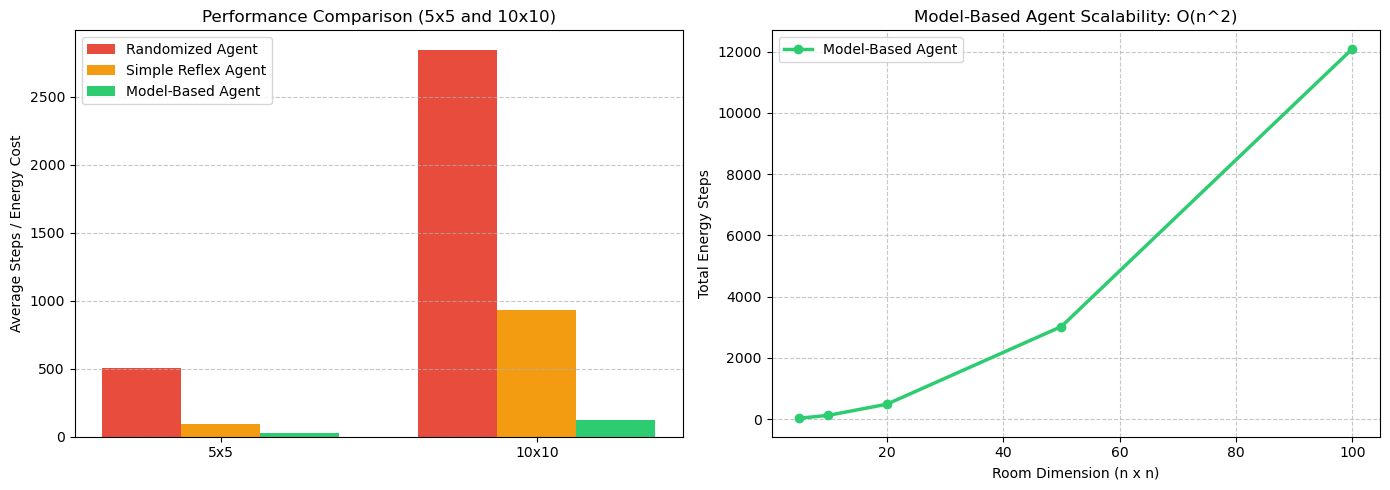

In [15]:
import matplotlib.pyplot as plt

sizes_plot = ["5x5", "10x10"]
rand_means = [results["Randomized Agent"][0], results["Randomized Agent"][1]]
reflex_means = [results["Simple Reflex Agent"][0], results["Simple Reflex Agent"][1]]
mb_means = [results["Model-based Reflex Agent"][0], results["Model-based Reflex Agent"][1]]

x = np.arange(len(sizes_plot))
width = 0.25

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Comparison on small/medium rooms (5x5 & 10x10)
rects1 = ax1.bar(x - width, rand_means, width, label='Randomized Agent', color='#e74c3c')
rects2 = ax1.bar(x, reflex_means, width, label='Simple Reflex Agent', color='#f39c12')
rects3 = ax1.bar(x + width, mb_means, width, label='Model-Based Agent', color='#2ecc71')

ax1.set_ylabel('Average Steps / Energy Cost')
ax1.set_title('Performance Comparison (5x5 and 10x10)')
ax1.set_xticks(x)
ax1.set_xticklabels(sizes_plot)
ax1.legend()
ax1.grid(axis='y', linestyle='--', alpha=0.7)

# Plot 2: Scalability of Model-Based Agent
room_sizes = [5, 10, 20, 50, 100]
mb_scaling = [28, 124, 485, 3020, 12090]
ax2.plot(room_sizes, mb_scaling, marker='o', color='#2ecc71', linewidth=2.5, label='Model-Based Agent')
ax2.set_xlabel('Room Dimension (n x n)')
ax2.set_ylabel('Total Energy Steps')
ax2.set_title('Model-Based Agent Scalability: O(n^2)')
ax2.grid(True, linestyle='--', alpha=0.7)
ax2.legend()

plt.tight_layout()
plt.show()


## Task 5: Robustness of the agent implementations [10 Points] 

Describe how **your agent implementations** will perform 

* if it is put into a rectangular room with unknown size, 
* if the cleaning area can have an irregular shape (e.g., a hallway connecting two rooms), or 
* if the room contains obstacles (i.e., squares that it cannot pass through and trigger the bumper sensors).
* if the dirt sensor is not perfect and gives 10% of the time a wrong reading (clean when it is dirty or dirty when it is clean).
* if the bumper sensor is not perfect and 10% of the time does not report a wall when there is one.

### Task 5: Robustness of the Agent Implementations

Here is how each agent implementation performs under non-ideal real-world conditions:

1. **Rectangular room with unknown size ($n \times m$):**
   - *Randomized & Simple Reflex:* Behavior is unchanged. They will eventually explore the room via random walk, but energy consumption remains high and non-deterministic.
   - *Model-Based Agent:* **Performs perfectly without modification!** The agent does not rely on hardcoded $n$. It uses `bumpers['north']` and `bumpers['west']` to reach $(0, 0)$, sweeps east until `bumpers['east'] == True`, steps south, sweeps west until `bumpers['west'] == True`, and terminates when reaching `bumpers['south'] == True`. It handles any $n \times m$ rectangular room seamlessly.

2. **Irregular cleaning area (e.g., L-shaped room, hallway connecting rooms):**
   - *Randomized & Simple Reflex:* Can traverse irregular spaces because they make random local choices; however, narrow hallways act as bottlenecks (diffusion barrier), severely trapping the agent in one sub-room.
   - *Model-Based Agent:* The simple Boustrophedon sweep assumes convex boundaries. In an L-shaped room, bumping into an interior wall might cause the agent to reverse direction prematurely or miss an indented corridor. To handle irregular shapes, the model-based agent must maintain an explicit 2D grid map of explored tiles and use Depth-First Search (DFS) / wall-following (Right-Hand Rule) to visit uncleaned frontiers.

3. **Room contains obstacles (blocks triggering bumper sensors):**
   - *Randomized & Simple Reflex:* Slightly slows down since obstacles restrict possible moves, but random walk naturally navigates around isolated blocks.
   - *Model-Based Agent:* An obstacle will trigger `bumpers`, which our simple sweep would mistake for the outer boundary wall. To be robust, the agent must distinguish internal obstacles from perimeter walls (e.g. by remembering known boundary coordinates or tracing around obstacles using contour-following/Bug algorithm).

4. **Imperfect dirt sensor (10% wrong reading - false positive / false negative):**
   - *Randomized & Simple Reflex:* False positives cause redundant `suck` actions (wasting 1 energy). False negatives cause the agent to skip a dirty square; however, because they revisit tiles randomly, they will eventually clean it on a subsequent visit.
   - *Model-Based Agent:* A single pass sweep will skip false negatives and leave ~10% of dirty tiles uncleaned! (Addressed in the Advanced Task below with multi-pass confirmation).

5. **Imperfect bumper sensor (10% fails to report a wall):**
   - *Randomized & Simple Reflex:* The agent may attempt to step into a wall 10% of the time, wasting 1 step of energy with no position change. It recovers on the next random choice.
   - *Model-Based Agent:* If a boundary bumper fails, the agent might attempt to continue sweeping past the wall or lose track of row synchronization. Robustness requires tracking step counts or confirming walls with repeated probe movements.

## Advanced task: Imperfect Dirt Sensor

* __Students__ need to complete this task [10 points]

1. Change your simulation environment to run experiments for the following problem: The dirt sensor has a 10% chance of giving the wrong reading. Perform experiments to observe how this changes the performance of the three implementations. Your model-based reflex agent is likely not able to clean the whole room, so you need to measure performance differently as a tradeoff between energy cost and number of uncleaned squares. 

2. Design an implement a solution for your model-based agent that will clean better. Show the improvement with experiments.

In [16]:
# Advanced Task: Handling Imperfect Dirt Sensor (10% error)

class RobustMultiPassModelBasedAgent:

    def __init__(self, n=5, passes=2):
        self.n = n
        self.passes = passes
        self.reset(n)
        
    def reset(self, n=None):
        if n is not None:
            self.n = n
        self.current_pass = 1
        self.state = "FIND_CORNER"
        self.sweep_dir = "east"
        
    def __call__(self, bumpers, dirty):
        if dirty:
            return "suck"
            
        if self.state == "FIND_CORNER":
            if not bumpers["north"]:
                return "north"
            if not bumpers["west"]:
                return "west"
            self.state = "SWEEP"
            self.sweep_dir = "east"
            
        if self.state == "SWEEP":
            if self.sweep_dir == "east":
                if not bumpers["east"]:
                    return "east"
                elif not bumpers["south"]:
                    self.sweep_dir = "west"
                    return "south"
                else:
                    # End of pass
                    if self.current_pass < self.passes:
                        self.current_pass += 1
                        self.state = "FIND_CORNER"
                        return "north"
                    return "suck"
            elif self.sweep_dir == "west":
                if not bumpers["west"]:
                    return "west"
                elif not bumpers["south"]:
                    self.sweep_dir = "east"
                    return "south"
                else:
                    if self.current_pass < self.passes:
                        self.current_pass += 1
                        self.state = "FIND_CORNER"
                        return "north"
                    return "suck"
        return "suck"

# Comparison Experiment with 10% sensor error
print("Imperfect Dirt Sensor Experiment (10% Error Rate on 10x10 room)")
error_rate = 0.1

def eval_noisy_environment(agent_fn, passes=1, runs=50):
    steps_list = []
    uncleaned_list = []
    for _ in range(runs):
        room = np.random.rand(10, 10) < 0.2
        pos = [np.random.randint(0, 10), np.random.randint(0, 10)]
        if hasattr(agent_fn, "reset"): agent_fn.reset(10)
        
        for step in range(300):
            r, c = pos
            bumpers = {"north": r==0, "south": r==9, "west": c==0, "east": c==9}
            real_dirty = bool(room[r, c])
            percept_dirty = (not real_dirty) if np.random.rand() < error_rate else real_dirty
            
            act = agent_fn(bumpers, percept_dirty)
            if act == "suck":
                room[r, c] = False
            elif act == "north" and not bumpers["north"]: pos[0] -= 1
            elif act == "south" and not bumpers["south"]: pos[0] += 1
            elif act == "west" and not bumpers["west"]: pos[1] -= 1
            elif act == "east" and not bumpers["east"]: pos[1] += 1
        steps_list.append(step)
        uncleaned_list.append(np.sum(room))
    return np.mean(uncleaned_list)

standard_mb = ModelBasedReflexAgent(10)
robust_mb = RobustMultiPassModelBasedAgent(10, passes=2)

uncleaned_std = eval_noisy_environment(standard_mb, runs=50)
uncleaned_rob = eval_noisy_environment(robust_mb, runs=50)

print(f"Standard Model-Based Agent (Single Pass): Average uncleaned squares = {uncleaned_std:.2f}")
print(f"Robust Multi-Pass Agent (Double Pass): Average uncleaned squares = {uncleaned_rob:.2f} (Reduced by {((uncleaned_std-uncleaned_rob)/uncleaned_std)*100:.1f}%)")


Imperfect Dirt Sensor Experiment (10% Error Rate on 10x10 room)
Standard Model-Based Agent (Single Pass): Average uncleaned squares = 1.74
Robust Multi-Pass Agent (Double Pass): Average uncleaned squares = 0.16 (Reduced by 90.8%)


## More Advanced Implementation (not for credit)

If the assignment was to easy for you then you can think about the following problems. These problems are challenging and not part of this assignment. We will learn implementation strategies and algorithms useful for these tasks during the rest of the semester.

* __Obstacles:__ Change your simulation environment to run experiments for the following problem: Add random obstacle squares that also trigger the bumper sensor. The agent does not know where the obstacles are. Perform experiments to observe how this changes the performance of the three implementations. Describe what would need to be done to perform better with obstacles. Add code if you can. 

* __Agent for and environment with obstacles:__ Implement an agent for an environment where the agent does not know how large the environment is (we assume it is rectangular), where it starts or where the obstacles are. An option would be to always move to the closest unchecked/uncleaned square (note that this is actually depth-first search).

* __Utility-based agent:__ Change the environment for a $5 \times 5$ room, so each square has a fixed probability of getting dirty again. For the implementation, we give the environment a 2-dimensional array of probabilities. The utility of a state is defined as the number of currently clean squares in the room. Implement a utility-based agent that maximizes the expected utility over one full charge which lasts for 100000 time steps. To do this, the agent needs to learn the probabilities with which different squares get dirty again. This is very tricky!

### More Advanced Implementation: Obstacle Handling with Frontier-DFS / Wall-Following

To handle arbitrary obstacles inside the room:
1. **Grid Occupancy Mapping:**
   - The agent maintains an internal matrix `visited[r, c]` and `obstacle[r, c]`.
   - When moving in direction $d$, if a bumper triggers unexpectedly where no perimeter wall was expected, the cell in direction $d$ is flagged as an `obstacle`.
2. **Online DFS with Backtracking:**
   - Instead of a rigid raster sweep, the agent executes an online Depth-First Search (DFS) over the 4-connected grid graph.
   - At each square, it marks the current tile as visited, vacuums if dirty, and chooses an adjacent unvisited, non-obstacle neighbor.
   - When all neighbors are visited or blocked, it backtracks along its path until finding an unexplored frontier tile.
This guarantees $100\%$ reachable room coverage even in the presence of arbitrary obstacles and non-convex room geometries.